# Chapitre 15 - Exercices 15.5 à 15.7

- **15.5** : corrélation d'échantillonnage entre deux arbres d'une forêt (formule (15.12)) ;
- **15.6** : sensibilité de la forêt au paramètre $m$ sur les données spam (erreurs OOB et test) ;
- **15.7** : importance par permutation en régression linéaire, $\mathbb E_P[\mathrm{RSS}^*_j-\mathrm{RSS}]=2\hat\beta_j^2$.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch15_forets as rf
set_style()

## Exercice 15.5 : Corrélation entre deux arbres d'une forêt

**Énoncé.** Montrer que la corrélation d'échantillonnage entre deux arbres d'une forêt
aléatoire, en un point $x$, vaut
$$\rho(x)=\frac{\operatorname{Var}_{\mathbf Z}\big[\mathbb E_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z))\big]}{\operatorname{Var}_{\mathbf Z}\big[\mathbb E_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z))\big]+\mathbb E_{\mathbf Z}\operatorname{Var}_{\Theta\mid\mathbf Z}\big[T(x;\Theta(\mathbf Z))\big]}.\qquad(15.12)$$
Le numérateur est $\operatorname{Var}_{\mathbf Z}[\hat f_{\rm rf}(x)]$ ; le second terme du
dénominateur est la variance conditionnelle moyenne due à la randomisation de la forêt.

### Cadre

On tire un échantillon d'apprentissage $\mathbf Z$, puis, **sachant $\mathbf Z$**, deux
aléas $\Theta_1,\Theta_2$ **indépendants et de même loi** (bootstrap + tirages des
variables candidates). On pose $T_k=T(x;\Theta_k(\mathbf Z))$, $k=1,2$. La corrélation
(15.6) est $\rho(x)=\operatorname{corr}(T_1,T_2)$, calculée sous la loi jointe de
$(\mathbf Z,\Theta_1,\Theta_2)$.

Rappelons les deux formules de décomposition (voir aussi l'exercice 15.4) :
$$\operatorname{Var}U=\mathbb E\big[\operatorname{Var}(U\mid\mathbf Z)\big]+\operatorname{Var}\big(\mathbb E[U\mid\mathbf Z]\big),\qquad
\operatorname{Cov}(U,V)=\mathbb E\big[\operatorname{Cov}(U,V\mid\mathbf Z)\big]+\operatorname{Cov}\big(\mathbb E[U\mid\mathbf Z],\mathbb E[V\mid\mathbf Z]\big).$$

### Démonstration

**Espérances conditionnelles.** $\Theta_1$ et $\Theta_2$ ayant la même loi sachant
$\mathbf Z$, $\mathbb E[T_1\mid\mathbf Z]=\mathbb E[T_2\mid\mathbf Z]=\mathbb E_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z))=\hat f_{\rm rf}(x)$
(la forêt limite (15.4)).

**Covariance.** Sachant $\mathbf Z$, $T_1$ et $T_2$ sont des fonctions respectives de
$\Theta_1$ et $\Theta_2$, qui sont indépendants : donc
$\operatorname{Cov}(T_1,T_2\mid\mathbf Z)=0$. La formule de la covariance totale donne
$$\operatorname{Cov}(T_1,T_2)=0+\operatorname{Cov}\big(\hat f_{\rm rf}(x),\hat f_{\rm rf}(x)\big)=\operatorname{Var}_{\mathbf Z}\hat f_{\rm rf}(x).$$

**Variance.** Pour $k=1,2$, la formule de la variance totale donne (c'est (15.9))
$$\operatorname{Var}T_k=\operatorname{Var}_{\mathbf Z}\hat f_{\rm rf}(x)+\mathbb E_{\mathbf Z}\operatorname{Var}_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z)).$$

**Conclusion.** Les deux variances étant égales,
$\rho(x)=\operatorname{Cov}(T_1,T_2)/\operatorname{Var}T_1$, ce qui est exactement (15.12). $\blacksquare$

> **Intuition.** Deux arbres construits sur le même $\mathbf Z$ ne se « ressemblent » qu'à
> travers $\mathbf Z$ : la part commune de leur variabilité est la variabilité de la forêt
> limite, la part propre à chacun est l'aléa $\Theta$. Plus la randomisation est forte
> (petit $m$), plus la part propre grandit et plus $\rho(x)$ est petit. Combinée à (15.5),
> on retrouve $\operatorname{Var}\hat f_{\rm rf}(x)=\rho(x)\sigma^2(x)$ avec
> $\sigma^2(x)=\operatorname{Var}T_1$.

### Vérification numérique sur le modèle (15.8)

$Y=\frac1{\sqrt{50}}\sum_{j=1}^{50}X_j+\varepsilon$. Nous tirons 200 échantillons
$\mathbf Z$ de taille 100 et, pour chacun, une forêt « maison » de 20 arbres ($m=10$,
$n_{\min}=5$), évaluée en 200 points $x$.

In [2]:
rng = np.random.RandomState(0)
Xtest, _, mu_test = rf.simuler_additif(200, rng=rng)
nZ, nT = 200, 20
T = np.empty((nZ, nT, len(Xtest)))
t0 = time.time()
for z in range(nZ):
    X, y, _ = rf.simuler_additif(100, rng=rng)
    T[z] = rf.ForetAleatoire(B=nT, m=10, nmin=5, seed=z).fit(X, y).predictions_arbres(Xtest)
print("temps : %.0f s" % (time.time() - t0))

temps : 7 s


**Formule (15.12)** (fonction `decomposition_variance`, qui estime les deux termes) contre
**corrélation empirique directe** entre des paires d'arbres $(T_{z,2k},T_{z,2k+1})$
construits sur le même échantillon, calculée point par point sur les $200\times10$ paires.

In [3]:
d = rf.decomposition_variance(T)
A = T[:, 0::2, :].reshape(-1, len(Xtest))
Bp = T[:, 1::2, :].reshape(-1, len(Xtest))
rho_direct = np.array([np.corrcoef(A[:, i], Bp[:, i])[0, 1] for i in range(len(Xtest))])
print("rho(x) moyen : formule (15.12) %.3f ; corrélation empirique directe %.3f"
      % (d["rho"].mean(), rho_direct.mean()))

rho(x) moyen : formule (15.12) 0.043 ; corrélation empirique directe 0.041


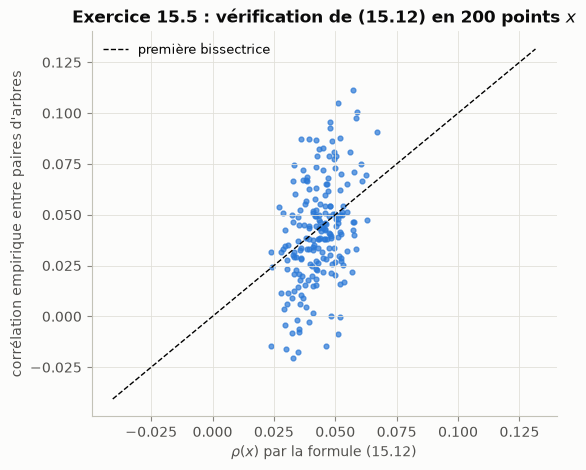

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(d["rho"], rho_direct, s=12, color=BLUE, alpha=0.7)
lim = [min(d["rho"].min(), rho_direct.min()) - 0.02, max(d["rho"].max(), rho_direct.max()) + 0.02]
ax.plot(lim, lim, "k--", lw=1, label="première bissectrice")
ax.set_xlabel(r"$\rho(x)$ par la formule (15.12)")
ax.set_ylabel(r"corrélation empirique entre paires d'arbres")
ax.set_title("Exercice 15.5 : vérification de (15.12) en 200 points $x$")
ax.legend()
plt.show()

Les points se dispersent autour de la bissectrice (chaque estimation ponctuelle est bruitée,
2000 paires seulement), et les moyennes concordent.

**Covariance conditionnelle nulle.** Fixons maintenant **un** échantillon $\mathbf Z$ et
tirons 400 arbres : les corrélations entre arbres pairs et impairs, calculées sur les 200
tirages de $\Theta$, doivent être nulles aux fluctuations près (écart-type
$\approx1/\sqrt{200}$).

In [5]:
X, y, _ = rf.simuler_additif(100, rng=rng)
foret_Z = rf.ForetAleatoire(B=400, m=10, nmin=5, seed=123).fit(X, y)
Pz = foret_Z.predictions_arbres(Xtest)
rho_cond = np.array([np.corrcoef(Pz[0::2, i], Pz[1::2, i])[0, 1] for i in range(len(Xtest))])
print("corrélation conditionnelle moyenne : %.4f (écart-type entre points %.3f ; 1/sqrt(200) = %.3f)"
      % (rho_cond.mean(), rho_cond.std(), 1 / np.sqrt(200)))

corrélation conditionnelle moyenne : 0.0003 (écart-type entre points 0.070 ; 1/sqrt(200) = 0.071)


Enfin, calculons la quantité contre laquelle le livre met en garde : la corrélation
entre arbres **ajustés** sur un même $\mathbf Z$, vus comme des vecteurs de prédictions
(corrélation calculée sur les points $x$, pas sur les tirages de $\mathbf Z$). C'est une
autre quantité, qui dépend de l'échantillon $\mathbf Z$ particulier et de la répartition
des points $x$, et qui n'intervient pas dans la variance de la forêt.

In [6]:
C = np.corrcoef(Pz[:50])
corr_vecteurs = C[np.triu_indices(50, 1)].mean()
print("corrélation moyenne entre vecteurs de prédictions d'arbres ajustés : %.3f" % corr_vecteurs)
print("à comparer à rho(x) moyen : %.3f" % d["rho"].mean())

corrélation moyenne entre vecteurs de prédictions d'arbres ajustés : 0.057
à comparer à rho(x) moyen : 0.043


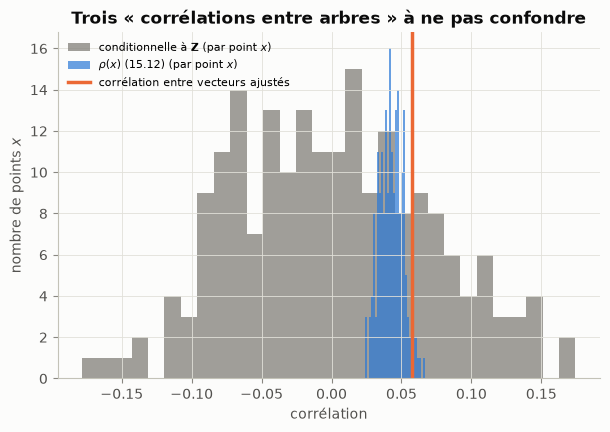

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(rho_cond, bins=30, color=GRAY, alpha=0.8, label=r"conditionnelle à $\mathbf{Z}$ (par point $x$)")
ax.hist(d["rho"], bins=30, color=BLUE, alpha=0.7, label=r"$\rho(x)$ (15.12) (par point $x$)")
ax.axvline(corr_vecteurs, color=ORANGE, lw=2.5, label="corrélation entre vecteurs ajustés")
ax.set_xlabel("corrélation")
ax.set_ylabel("nombre de points $x$")
ax.set_title("Trois « corrélations entre arbres » à ne pas confondre")
ax.legend(fontsize=8)
plt.show()

> **À retenir.** $\operatorname{Cov}(T_1,T_2)=\operatorname{Var}_{\mathbf Z}\hat f_{\rm rf}(x)$
> car les arbres sont indépendants sachant $\mathbf Z$ ; d'où (15.12). La corrélation
> $\rho(x)$ provient **uniquement** de la variabilité de l'échantillon ; elle n'a rien à
> voir avec la corrélation entre les vecteurs de prédictions d'arbres déjà ajustés,
> même si, dans cet exemple, les deux sont d'un ordre de grandeur comparable.

## Exercice 15.6 : Sensibilité au paramètre $m$ sur les données spam

**Énoncé.** Ajuster une série de forêts aléatoires aux données spam pour explorer la
sensibilité au paramètre $m$. Tracer l'erreur OOB et l'erreur test en fonction de $m$,
sur une plage de valeurs bien choisie.

### Démarche

- Données : séparation apprentissage (3065) / test (1536) de `rf.separer_spam`, comme dans
  les notebooks de cours.
- Plage de $m$ : de 1 à $p=57$ ($m=57$ est le bagging), plus serrée autour de la valeur par
  défaut $\lfloor\sqrt{57}\rfloor=7$, où l'on s'attend à l'optimum.
- Pour chaque $m$ : une forêt de 300 arbres (l'erreur OOB est stabilisée bien avant, cf.
  figure 15.4). Pour aller vite sur les 14 valeurs × 3 graines, nous utilisons
  `RandomForestClassifier` de scikit-learn, dont l'option `oob_score=True` calcule l'erreur
  OOB exactement comme notre fonction `erreur_oob_cumulee` (contrôle ci-dessous).

In [8]:
from sklearn.ensemble import RandomForestClassifier

spam = datasets.load_spam()
Xtr, ytr, Xte, yte = rf.separer_spam(spam)

# contrôle : OOB scikit-learn vs notre calcul à partir des arbres et des échantillons bootstrap
mod = RandomForestClassifier(100, max_features=7, oob_score=True, n_jobs=-1, random_state=0).fit(Xtr, ytr)
P = np.array([e.predict_proba(Xtr)[:, 1] for e in mod.estimators_])
dans_sac = np.zeros(P.shape, dtype=bool)
for b, idx in enumerate(mod.estimators_samples_):
    dans_sac[b, idx] = True
hors = ~dans_sac
f_oob = (P * hors).sum(0) / hors.sum(0)
print("OOB scikit-learn : %.4f ; recalculée : %.4f" % (1 - mod.oob_score_, np.mean((f_oob > 0.5) != ytr)))

OOB scikit-learn : 0.0529 ; recalculée : 0.0529


(scikit-learn moyenne les probabilités des arbres plutôt que leurs votes ; avec des arbres
complets, dont les feuilles sont presque toutes pures, c'est quasiment la même chose.)

In [9]:
m_grille = [1, 2, 3, 4, 5, 6, 7, 8, 10, 13, 17, 25, 40, 57]
graines = [0, 1, 2]
err_oob = np.zeros((len(graines), len(m_grille)))
err_test = np.zeros((len(graines), len(m_grille)))
t0 = time.time()
for g, s in enumerate(graines):
    for k, m in enumerate(m_grille):
        mod = RandomForestClassifier(300, max_features=m, oob_score=True, n_jobs=-1, random_state=s).fit(Xtr, ytr)
        err_oob[g, k] = 1 - mod.oob_score_
        err_test[g, k] = np.mean(mod.predict(Xte) != yte)
print("temps : %.0f s" % (time.time() - t0))

temps : 14 s


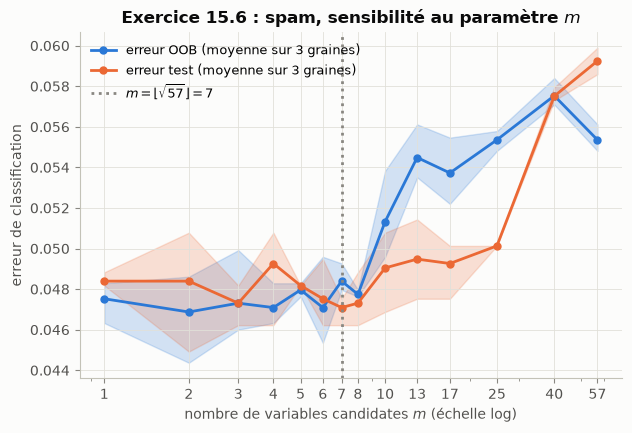

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for E, nom, c in [(err_oob, "erreur OOB", BLUE), (err_test, "erreur test", ORANGE)]:
    ax.plot(m_grille, E.mean(0), "o-", color=c, label=nom + " (moyenne sur 3 graines)")
    ax.fill_between(m_grille, E.min(0), E.max(0), color=c, alpha=0.2)
ax.axvline(7, color=GRAY, ls=":", label=r"$m=\lfloor\sqrt{57}\rfloor=7$")
ax.set_xscale("log")
ax.set_xticks(m_grille, m_grille)
ax.set_xlabel("nombre de variables candidates $m$ (échelle log)")
ax.set_ylabel("erreur de classification")
ax.set_title("Exercice 15.6 : spam, sensibilité au paramètre $m$")
ax.legend()
plt.show()

In [11]:
for k, m in enumerate(m_grille):
    print("m = %2d : OOB %.4f   test %.4f" % (m, err_oob[:, k].mean(), err_test[:, k].mean()))

m =  1 : OOB 0.0475   test 0.0484
m =  2 : OOB 0.0469   test 0.0484
m =  3 : OOB 0.0473   test 0.0473
m =  4 : OOB 0.0471   test 0.0493
m =  5 : OOB 0.0480   test 0.0482
m =  6 : OOB 0.0471   test 0.0475
m =  7 : OOB 0.0484   test 0.0471
m =  8 : OOB 0.0477   test 0.0473
m = 10 : OOB 0.0513   test 0.0490
m = 13 : OOB 0.0545   test 0.0495
m = 17 : OOB 0.0537   test 0.0493
m = 25 : OOB 0.0554   test 0.0501
m = 40 : OOB 0.0575   test 0.0575
m = 57 : OOB 0.0554   test 0.0592


### Commentaires

- Les deux courbes ont la même forme : l'erreur OOB, calculée sur les seules données
  d'apprentissage, suffit pour **choisir $m$**.
- L'erreur est minimale et pratiquement **constante** pour les petites valeurs de $m$
  (de 1 à 8 environ, autour de la valeur par défaut $\sqrt p$) : c'est ce qui vaut aux
  forêts leur réputation d'être peu sensibles au réglage. Les différences entre ces
  valeurs (quelques courriels sur 1536) sont de l'ordre des fluctuations entre graines.
- À partir de $m\approx10$ l'erreur augmente, jusqu'au bagging ($m=57$) : les arbres,
  qui choisissent presque tous les mêmes variables fortes, sont trop corrélés et la
  variance de la forêt augmente. (Le biais accru attendu pour $m$ très petit n'est pas
  visible ici.)

> **À retenir.** $m$ règle le compromis biais/variance de la forêt ; l'erreur OOB permet
> de le choisir sans ensemble de validation. Sur spam, toute valeur entre 3 et 10 environ
> convient.

## Exercice 15.7 : Importance par permutation en régression linéaire

**Énoncé.** On ajuste un modèle de régression linéaire par moindres carrés sur $N$
observations, de réponse $y_i$ et de prédicteurs $x_{i1},\dots,x_{ip}$, toutes les variables
étant standardisées (moyenne nulle, écart-type 1). Soit $\mathrm{RSS}$ l'erreur quadratique
moyenne d'apprentissage et $\hat\beta$ les coefficients estimés. Soit $\mathrm{RSS}^*_j$
l'erreur quadratique moyenne d'apprentissage obtenue avec le même $\hat\beta$, mais après
avoir permuté aléatoirement les $N$ valeurs de la $j$-ième variable. Montrer que
$$\mathbb E_P\big[\mathrm{RSS}^*_j-\mathrm{RSS}\big]=2\hat\beta_j^2,\qquad(15.13)$$
où $\mathbb E_P$ est l'espérance sous la loi (uniforme) des permutations. Expliquer
pourquoi c'est approximativement vrai lorsque l'évaluation se fait sur un ensemble test
indépendant.

### Notations et rappels

- Standardisation : $\frac1N\sum_ix_{ij}=0$ et $\frac1N\sum_ix_{ij}^2=1$ (écart-type « en
  $1/N$ ») pour tout $j$.
- Résidus $r_i=y_i-x_i^T\hat\beta$ et $\mathrm{RSS}=\frac1N\sum_ir_i^2$.
- **Équations normales** : $\hat\beta$ minimise $\sum_i(y_i-x_i^T\beta)^2$, donc le gradient
  s'annule : $\mathbf X^T(\mathbf y-\mathbf X\hat\beta)=0$, soit $\sum_ir_ix_{ij}=0$ pour
  tout $j$ (les résidus sont orthogonaux à chaque variable).
- $\pi$ est une permutation uniforme de $\{1,\dots,N\}$ : pour chaque $i$, $\pi(i)$ est
  uniforme sur $\{1,\dots,N\}$, d'où $\mathbb E_P[x_{\pi(i)j}]=\frac1N\sum_kx_{kj}=0$ et
  $\mathbb E_P[x_{\pi(i)j}^2]=\frac1N\sum_kx_{kj}^2=1$.

### Démonstration

Après permutation de la colonne $j$, la prédiction pour $i$ devient
$x_i^T\hat\beta-\hat\beta_jx_{ij}+\hat\beta_jx_{\pi(i)j}$, donc le résidu devient
$$r^*_i=r_i+\hat\beta_j\,d_i,\qquad d_i=x_{ij}-x_{\pi(i)j}.$$
On développe le carré :
$$\mathrm{RSS}^*_j=\frac1N\sum_i(r_i+\hat\beta_jd_i)^2=\mathrm{RSS}+\frac{2\hat\beta_j}N\sum_ir_id_i+\frac{\hat\beta_j^2}N\sum_id_i^2 .$$

**Terme croisé.** Par linéarité de l'espérance,
$\mathbb E_P\big[\sum_ir_id_i\big]=\sum_ir_ix_{ij}-\sum_ir_i\,\mathbb E_P[x_{\pi(i)j}]=0-0=0$ :
le premier morceau est nul par les équations normales, le second car la variable est
centrée.

**Terme quadratique.** On développe $d_i^2=x_{ij}^2-2x_{ij}x_{\pi(i)j}+x_{\pi(i)j}^2$ :
$$\mathbb E_P\Big[\frac1N\sum_id_i^2\Big]=\frac1N\sum_ix_{ij}^2-\frac2N\sum_ix_{ij}\,\mathbb E_P[x_{\pi(i)j}]+\frac1N\sum_i\mathbb E_P[x_{\pi(i)j}^2]=1-0+1=2 .$$

**Conclusion.** $\mathbb E_P[\mathrm{RSS}^*_j-\mathrm{RSS}]=0+2\hat\beta_j^2$. $\blacksquare$

> **Remarque.** La standardisation de $y$ n'intervient pas. Sans supposer les variables
> standardisées, le même calcul donne
> $\mathbb E_P[\mathrm{RSS}^*_j-\mathrm{RSS}]=2\hat\beta_j^2\,\widehat{\operatorname{Var}}(x_j)$ (variance empirique en
> $1/N$) si le modèle contient une constante ; c'est ce que calcule la fonction
> `esperance_hausse_rss` (sans aucune hypothèse). Permuter une variable revient, en
> moyenne, à la remplacer par une copie indépendante de même loi : on « annule » son
> effet comme si l'on mettait $\hat\beta_j$ à zéro, et le prix est proportionnel à $\hat\beta_j^2$.

### Vérification exacte par énumération

Pour $N=7$ il y a $7!=5040$ permutations : on peut calculer $\mathbb E_P$ exactement.

In [12]:
import itertools

rng = np.random.RandomState(0)
N, p = 7, 3
X = rng.randn(N, p)
y = X @ np.array([1.0, -0.5, 0.2]) + 0.5 * rng.randn(N)
X = (X - X.mean(0)) / X.std(0)
y = (y - y.mean()) / y.std()
beta = np.linalg.lstsq(X, y, rcond=None)[0]
rss = np.mean((y - X @ beta) ** 2)
perms = [np.array(s) for s in itertools.permutations(range(N))]
for j in range(p):
    moy = np.mean([rf.rss_permute(X, y, beta, j, s) for s in perms]) - rss
    print("j = %d : E_P[RSS*_j - RSS] = %.6f   2 beta_j^2 = %.6f" % (j, moy, 2 * beta[j] ** 2))

j = 0 : E_P[RSS*_j - RSS] = 1.241724   2 beta_j^2 = 1.241724
j = 1 : E_P[RSS*_j - RSS] = 0.260719   2 beta_j^2 = 0.260719
j = 2 : E_P[RSS*_j - RSS] = 0.424161   2 beta_j^2 = 0.424161


### Sur un ensemble test indépendant

Sur un ensemble test $(\tilde x_i,\tilde y_i)_{i\le M}$, le même développement donne
$$\mathbb E_P\big[\mathrm{RSS}^{*,\rm test}_j-\mathrm{RSS}^{\rm test}\big]=\frac{2\hat\beta_j}M\sum_i\tilde r_i(\tilde x_{ij}-\bar{\tilde x}_j)+\frac{\hat\beta_j^2}M\sum_i\mathbb E_P\big[(\tilde x_{ij}-\tilde x_{\pi(i)j})^2\big].$$

- Le second terme vaut $2\hat\beta_j^2\,\widehat{\operatorname{Var}}(\tilde x_j)\approx2\hat\beta_j^2$, car les
  données test suivent la même loi (variance $\approx1$).
- Le premier terme est $2\hat\beta_j$ fois la covariance empirique entre les résidus test et
  $\tilde x_j$. Les équations normales ne s'appliquent plus, mais si le modèle linéaire est
  correct, $\tilde r_i=\tilde\varepsilon_i+\tilde x_i^T(\beta-\hat\beta)$ : la covariance vaut
  environ $\operatorname{Cov}(\tilde x_j,\tilde x^T)(\beta-\hat\beta)$, qui est petite (d'ordre
  $1/\sqrt N$), plus un terme de bruit d'ordre $1/\sqrt M$.

D'où l'approximation $\approx2\hat\beta_j^2$ sur un ensemble test.

In [13]:
rng = np.random.RandomState(1)
N, M, p = 1000, 5000, 6
beta_vrai = np.array([1.0, 0.7, -0.5, 0.3, 0.1, 0.0])
def simu(n):
    Xs = rng.randn(n, p)
    return Xs, Xs @ beta_vrai + rng.randn(n)
X, y = simu(N)
Xt, yt = simu(M)
moy_x, ec_x, moy_y, ec_y = X.mean(0), X.std(0), y.mean(), y.std()
X, Xt = (X - moy_x) / ec_x, (Xt - moy_x) / ec_x
y, yt = (y - moy_y) / ec_y, (yt - moy_y) / ec_y
beta = np.linalg.lstsq(X, y, rcond=None)[0]
rss_tr, rss_te = np.mean((y - X @ beta) ** 2), np.mean((yt - Xt @ beta) ** 2)
n_perm = 300
hausse_tr = np.array([[rf.rss_permute(X, y, beta, j, rng.permutation(N)) - rss_tr for _ in range(n_perm)] for j in range(p)])
hausse_te = np.array([[rf.rss_permute(Xt, yt, beta, j, rng.permutation(M)) - rss_te for _ in range(n_perm)] for j in range(p)])

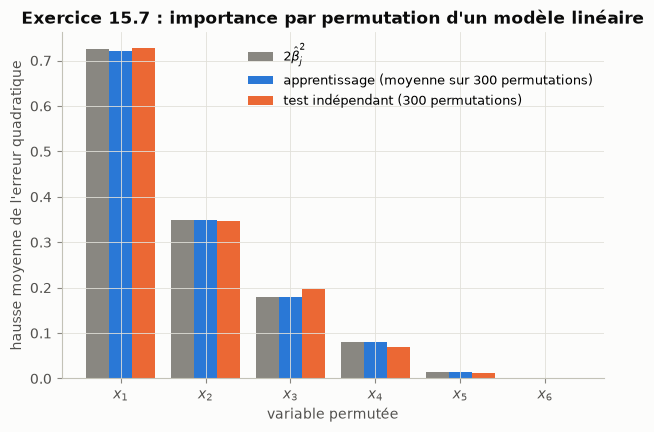

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
pos = np.arange(p)
ax.bar(pos - 0.27, 2 * beta ** 2, width=0.27, color=GRAY, label=r"$2\hat\beta_j^2$")
ax.bar(pos, hausse_tr.mean(1), width=0.27, color=BLUE, label="apprentissage (moyenne sur 300 permutations)")
ax.bar(pos + 0.27, hausse_te.mean(1), width=0.27, color=ORANGE, label="test indépendant (300 permutations)")
ax.set_xticks(pos, ["$x_%d$" % (j + 1) for j in range(p)])
ax.set_xlabel("variable permutée")
ax.set_ylabel(r"hausse moyenne de l'erreur quadratique")
ax.set_title("Exercice 15.7 : importance par permutation d'un modèle linéaire")
ax.legend()
plt.show()

In [15]:
for j in range(p):
    print("x%d : 2 beta^2 = %.4f   apprentissage %.4f   test %.4f   (formule exacte apprentissage : %.4f)"
          % (j + 1, 2 * beta[j] ** 2, hausse_tr[j].mean(), hausse_te[j].mean(),
             rf.esperance_hausse_rss(X, y, beta, j)))

x1 : 2 beta^2 = 0.7244   apprentissage 0.7212   test 0.7265   (formule exacte apprentissage : 0.7244)
x2 : 2 beta^2 = 0.3493   apprentissage 0.3500   test 0.3473   (formule exacte apprentissage : 0.3493)
x3 : 2 beta^2 = 0.1796   apprentissage 0.1797   test 0.1977   (formule exacte apprentissage : 0.1796)
x4 : 2 beta^2 = 0.0800   apprentissage 0.0807   test 0.0703   (formule exacte apprentissage : 0.0800)
x5 : 2 beta^2 = 0.0139   apprentissage 0.0139   test 0.0114   (formule exacte apprentissage : 0.0139)
x6 : 2 beta^2 = 0.0001   apprentissage 0.0001   test 0.0002   (formule exacte apprentissage : 0.0001)


Sur l'apprentissage, les moyennes sur 300 permutations sont proches de $2\hat\beta_j^2$
(la petite différence est l'erreur de Monte-Carlo ; la formule exacte coïncide). Sur le
test, l'accord n'est qu'approché : les écarts proviennent de l'erreur d'estimation
$\hat\beta-\beta$ (d'ordre $1/\sqrt N$), du bruit des données test (d'ordre $1/\sqrt M$)
et de ce que la variance empirique de $\tilde x_j$ n'est pas exactement 1 ; ils
diminuent quand $N$ et $M$ augmentent.

> **À retenir.** En régression linéaire standardisée, permuter la variable $j$ augmente en
> moyenne l'erreur quadratique de $2\hat\beta_j^2$ (exactement sur l'apprentissage, grâce
> aux équations normales ; approximativement sur un test). L'importance par permutation
> des forêts est donc l'analogue non linéaire de « mettre le coefficient à zéro ».